# Bag-of-N-Grams

In [4]:
from sklearn.feature_extraction.text import CountVectorizer

###  Initializing CountVectorizer (Unigrams)

In [3]:
v = CountVectorizer()
v.fit(["Natural language processing is fascinating"])

v.vocabulary_

{'natural': 3, 'language': 2, 'processing': 4, 'is': 1, 'fascinating': 0}

### Using Bigrams (ngram_range=(2,2))

In [10]:
v = CountVectorizer(ngram_range=(2,2))
v.fit(["Natural language processing is fascinating"],)

v.vocabulary_

{'natural language': 2,
 'language processing': 1,
 'processing is': 3,
 'is fascinating': 0}

###  Using Trigrams (ngram_range=(3,3))

In [9]:
v = CountVectorizer(ngram_range=(3,3))
v.fit(["Natural language processing is fascinating"],)

v.vocabulary_

{'natural language processing': 1,
 'language processing is': 0,
 'processing is fascinating': 2}

### Using unigrams, bigrams and trigrams (ngram_range=(1,3))

In [11]:
v = CountVectorizer(ngram_range=(1,3))
v.fit(["Natural language processing is fascinating"],)

v.vocabulary_

{'natural': 6,
 'language': 3,
 'processing': 9,
 'is': 1,
 'fascinating': 0,
 'natural language': 7,
 'language processing': 4,
 'processing is': 10,
 'is fascinating': 2,
 'natural language processing': 8,
 'language processing is': 5,
 'processing is fascinating': 11}

## Application ex : We take a simple collection of text documents, preprocess them to remove stop words, lemmatize etc and then generate bag of 1 grams and 2 grams from it

In [12]:
import spacy

In [17]:
corpus = [
    "Cloud computing platforms provide scalable infrastructure and storage solutions.",
    "Developers use Git version control to collaborate on software engineering projects."
]

In [18]:
nlp = spacy.load("en_core_web_sm")

def preprocess(text):
    doc = nlp(text)
    filtered_tokens = []
    for token in doc:
        if not token.is_stop and not token.is_punct:
            filtered_tokens.append(token.lemma_)
    return " ".join(filtered_tokens)

preprocess("This is an example.")

'example'

In [19]:
corpus_processed = [preprocess(text) for text in corpus]
corpus_processed

['Cloud computing platform provide scalable infrastructure storage solution',
 'developer use Git version control collaborate software engineering project']

In [20]:
v = CountVectorizer(ngram_range=(1,2))
v.fit(corpus_processed)

v.vocabulary_

{'cloud': 0,
 'computing': 4,
 'platform': 16,
 'provide': 19,
 'scalable': 21,
 'infrastructure': 14,
 'storage': 26,
 'solution': 25,
 'cloud computing': 1,
 'computing platform': 5,
 'platform provide': 17,
 'provide scalable': 20,
 'scalable infrastructure': 22,
 'infrastructure storage': 15,
 'storage solution': 27,
 'developer': 8,
 'use': 28,
 'git': 12,
 'version': 30,
 'control': 6,
 'collaborate': 2,
 'software': 23,
 'engineering': 10,
 'project': 18,
 'developer use': 9,
 'use git': 29,
 'git version': 13,
 'version control': 31,
 'control collaborate': 7,
 'collaborate software': 3,
 'software engineering': 24,
 'engineering project': 11}

### Transforming the Corpus into a Document-Term Matrix

Once our `CountVectorizer` has been fitted to the processed corpus, we use `v.transform(corpus_processed)` to convert our documents into a sparse bag-of-words matrix.

* **`v.transform(...)`**: Counts the occurrences of each token (unigram and bigram) defined in our vocabulary for each document in our processed corpus.
* **`.toarray()`**: Converts the sparse matrix output of `transform` into a dense NumPy array so we can easily view the bag-of-words representation for each document. Each row represents a document, and each column represents a specific unigram or bigram from our learned vocabulary, with the cell value indicating the token count.

#### Example of how to interpret the output array:

If we look at the first two elements in our learned vocabulary:
* Index `0` represents the word **"cloud"**
* Index `1` represents the bigram **"cloud computing"**

When we call `.toarray()`, the first row corresponds to our first document: `"Cloud computing platform..."`:
* At column index `0`, the value is `1` (because **"cloud"** appears once).
* At column index `1`, the value is `1` (because **"cloud computing"** appears once).

For the second row corresponding to our second document: `"developer use Git..."`:
* At column index `0`, the value is `0` (the word **"cloud"** does not appear).
* At column index `1`, the value is `0` (the bigram **"cloud computing"** does not appear).

In [24]:
v.transform(corpus_processed).toarray()

array([[1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1,
        1, 0, 0, 1, 1, 1, 0, 0, 0, 0],
       [0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0,
        0, 1, 1, 0, 0, 0, 1, 1, 1, 1]])

---


# Application : News Category Classification Problem

Here we want to do a news category classification. We will use bag of n-grams and train a machine learning model that can categorize any news into one of the following categories:

    0 BUSINESS
    1 SPORTS
    2 CRIME
    3 SCIENCE


In [25]:
import pandas as pd

Dataset

Dataset Credits: https://www.kaggle.com/code/hengzheng/news-category-classifier-val-acc-0-65 & https://github.com/codebasics/nlp-tutorials

In [33]:
FILE_PATH = "/content/news_dataset.json" # to change with your path
df = pd.read_json(FILE_PATH)
print(f"data frame size:  {df.shape[0]} rows , and {df.shape[1]} cols.")
df.head()

data frame size:  12695 rows , and 2 cols.


,text,category
0,Watching Schrödinger's Cat Die University of C...,SCIENCE
1,WATCH: Freaky Vortex Opens Up In Flooded Lake,SCIENCE
2,Entrepreneurs Today Don't Need a Big Budget to...,BUSINESS
3,These Roads Could Recharge Your Electric Car A...,BUSINESS
4,Civilian 'Guard' Fires Gun While 'Protecting' ...,CRIME


In [35]:
df.category.value_counts()

,count
category,
BUSINESS,4254
SPORTS,4167
CRIME,2893
SCIENCE,1381


There is imbalanced data in target y (category).... and to Handle class imbalance we will use undersampling technique

In [36]:
min_samples = 1381

df_business = df[df.category == 'BUSINESS'].sample(min_samples, random_state=42)
df_sport = df[df.category == 'SPORTS'].sample(min_samples, random_state=42)
df_crime = df[df.category == 'CRIME'].sample(min_samples, random_state=42)
df_science = df[df.category == 'SCIENCE'].sample(min_samples, random_state=42)

df_balanced = pd.concat([df_business, df_sport, df_crime, df_science], axis=0)

In [37]:
df_balanced.category.value_counts()

,count
category,
BUSINESS,1381
SPORTS,1381
CRIME,1381
SCIENCE,1381


In [52]:
df_balanced.shape[0]

5524

## Convert the target (text category) to a number

In [38]:
TARGET = {'BUSINESS':0, 'SPORTS':1, 'CRIME':2, 'SCIENCE':3}
df_balanced['target'] = df_balanced.category.map(TARGET)

In [39]:
df_balanced.head()

,text,category,target
594,How to Develop the Next Generation of Innovato...,BUSINESS,0
3093,"Madoff Victims' Payout Nears $7.2 Billion, Tru...",BUSINESS,0
7447,Bay Area Floats 'Sanctuary In Transit Policy' ...,BUSINESS,0
10388,Microsoft Agrees To Acquire LinkedIn For $26.2...,BUSINESS,0
1782,"Inside A Legal, Multibillion Dollar Weed Market",BUSINESS,0


# Test Train split (Stratefied split 80/20)

In [43]:
from sklearn.model_selection import train_test_split

X = df_balanced.text
y = df_balanced.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [57]:
print(f"X_train size:  {X_train.shape[0]} rows ")
print(f"X_test size:  {X_test.shape[0]} rows ")
print(f"y train class rate:\n {y_train.value_counts()/y_train.shape[0]}")
print(f"y train class rate:\n {y_test.value_counts()/y_test.shape[0]}")

X_train size:  4419 rows 
X_test size:  1105 rows 
y train class rate:
 target
0    0.250057
3    0.250057
1    0.250057
2    0.249830
Name: count, dtype: float64
y train class rate:
 target
2    0.250679
0    0.249774
1    0.249774
3    0.249774
Name: count, dtype: float64


# 1. Build a model with original text (no pre processing)

In [58]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report


## 1.1 Attempt 1 : Use 1-gram which is nothing but a Bag Of Words (BOW) model

In [62]:
model_1_1 = Pipeline(
    [
        ("vectorizer_bow", CountVectorizer()), # equiv ngram_range(1,1) parameter
        ("multi_nb", MultinomialNB())
    ]
)

model_1_1.fit(X_train, y_train)

y_pred = model_1_1.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.92      0.84       276
           1       0.92      0.85      0.88       276
           2       0.91      0.89      0.90       277
           3       0.89      0.82      0.85       276

    accuracy                           0.87      1105
   macro avg       0.88      0.87      0.87      1105
weighted avg       0.88      0.87      0.87      1105



In [64]:
print(f"X test (3 first rows) \n {X_test[:3]}")
print(f"y test (3 first rows) \n   {y_test[:3]}")
print(f"y pred (3 first rows) \n {y_pred[:3]}")

X test (3 first rows) 
 12446    Shocking Video Of Officer Punching Woman Ignit...
3868     YOLO ATTACK: Birthday Stabbing Turns Party Int...
3301                             Great News For Obamacare 
Name: text, dtype: object
y test (3 first rows) 
   12446    2
3868     2
3301     0
Name: target, dtype: int64
y pred (3 first rows) 
 [2 2 0]


## 1.2 Attempt 2 : Use 1-gram and bigrams

In [66]:
model_1_2 = Pipeline(
    [
        ("vectorizer_bow", CountVectorizer(ngram_range=(1,2))),
        ("multi_nb", MultinomialNB())
    ]
)

model_1_2.fit(X_train, y_train)

y_pred = model_1_2.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.73      0.95      0.82       276
           1       0.92      0.83      0.87       276
           2       0.91      0.88      0.89       277
           3       0.93      0.79      0.85       276

    accuracy                           0.86      1105
   macro avg       0.87      0.86      0.86      1105
weighted avg       0.87      0.86      0.86      1105



# 2. Build a model with original text (no pre processing)

we have not done any text-processing yet to remove stop words, punctuations, apply lemmatization etc. Well we wanted to train the model without any preprocessing first and check the performance. Now we will re-do same thing but with preprocessing of text

In [71]:
df_balanced['preprocessed_txt'] = df_balanced['text'].apply(preprocess)

In [72]:
df_balanced.head()

,text,category,target,preprocessed_txt
594,How to Develop the Next Generation of Innovato...,BUSINESS,0,develop Generation Innovators stop treat way g...
3093,"Madoff Victims' Payout Nears $7.2 Billion, Tru...",BUSINESS,0,Madoff Victims Payout near $ 7.2 billion Trust...
7447,Bay Area Floats 'Sanctuary In Transit Policy' ...,BUSINESS,0,Bay Area Floats Sanctuary Transit Policy prote...
10388,Microsoft Agrees To Acquire LinkedIn For $26.2...,BUSINESS,0,Microsoft agree acquire linkedin $ 26.2 billio...
1782,"Inside A Legal, Multibillion Dollar Weed Market",BUSINESS,0,inside Legal Multibillion Dollar Weed Market


In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    df_balanced.preprocessed_txt,
    df_balanced.target,
    test_size=0.2,
    random_state=2022,
    stratify=df_balanced.target
)



In [76]:


model_2 = Pipeline([
    ('vectorizer_bow', CountVectorizer(ngram_range = (1, 2))),
    ('Multi NB', MultinomialNB())
])

model_2.fit(X_train, y_train)


y_pred = model_2.predict(X_test)

print(classification_report(y_test, y_pred))



              precision    recall  f1-score   support

           0       0.79      0.90      0.84       276
           1       0.93      0.82      0.87       277
           2       0.84      0.92      0.88       276
           3       0.91      0.82      0.86       276

    accuracy                           0.86      1105
   macro avg       0.87      0.86      0.86      1105
weighted avg       0.87      0.86      0.86      1105



Text(95.72222222222221, 0.5, 'Truth')

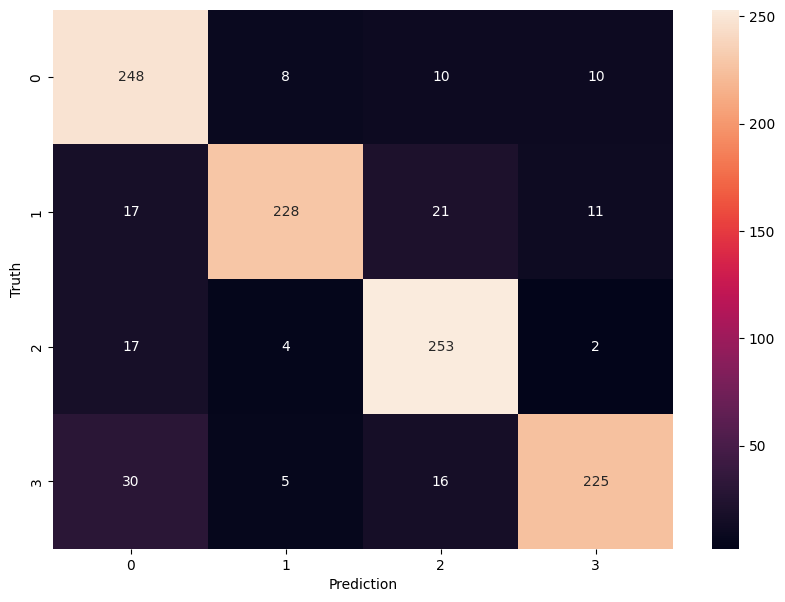

In [77]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sn


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize = (10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Prediction')
plt.ylabel('Truth')